# Chapitre 10 - Exercices 10.1 à 10.6

Ce notebook traite les exercices 10.1 à 10.6 : le coefficient d'AdaBoost, le minimiseur de
la perte exponentielle, dépendance partielle et espérance conditionnelle, AdaBoost avec
des arbres (simulation (10.2) et classes qui se chevauchent), la perte exponentielle
multiclasse et le test de McNemar.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import optimize, stats
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl import datasets
from esl.ch10_boosting import (AdaBoostM1, GradientBoosting, RegressionTree,
                               simulate_nested_spheres, partial_dependence_bruteforce)

## Exercice 10.1 : Le coefficient $\beta_m$ d'AdaBoost

**Énoncé (reformulé).** Établir l'expression (10.12) du coefficient de mise à jour
d'AdaBoost : $\beta_m = \frac12\log\frac{1-\mathrm{err}_m}{\mathrm{err}_m}$.

**Rappels.** À l'étape $m$ de la modélisation pas à pas avec la perte exponentielle, on
cherche (éq. (10.9))

$$(\beta_m, G_m) = \arg\min_{\beta, G}\sum_{i=1}^N w_i^{(m)}\exp\big(-\beta\, y_i G(x_i)\big),
\qquad w_i^{(m)} = \exp\big(-y_i f_{m-1}(x_i)\big) > 0,$$

où $y_i \in\{-1,1\}$ et $G(x_i)\in\{-1,1\}$. L'erreur pondérée de $G$ est
$\mathrm{err} = \sum_i w_i^{(m)} I(y_i\ne G(x_i)) / \sum_i w_i^{(m)}$.

**Solution.**

*Étape 1 : réécriture.* Le produit $y_iG(x_i)$ vaut $+1$ si $x_i$ est bien classé et $-1$
sinon. Notons $W = \sum_i w_i^{(m)}$ et $W_{\text{err}} = \sum_i w_i^{(m)} I(y_i \ne G(x_i)) = W\,\mathrm{err}$. Alors

$$J(\beta) := \sum_i w_i^{(m)}e^{-\beta y_iG(x_i)} = e^{-\beta}\,(W - W_{\text{err}}) + e^{\beta}\,W_{\text{err}}
= W\big[e^{-\beta}(1-\mathrm{err}) + e^{\beta}\mathrm{err}\big].$$

*Étape 2 : choix de $G$.* On a aussi $J = (e^\beta - e^{-\beta})W_{\text{err}} + e^{-\beta}W$ (éq. (10.11)). Pour
tout $\beta > 0$, le coefficient $e^\beta - e^{-\beta}$ est positif : le meilleur $G$ est celui
qui minimise $W_{\text{err}}$, quel que soit $\beta>0$. On peut donc d'abord choisir $G_m$
(éq. (10.10)), puis optimiser $\beta$ avec $\mathrm{err} = \mathrm{err}_m$ fixé.

*Étape 3 : optimisation en $\beta$.* La fonction $h(\beta) = e^{-\beta}(1-\mathrm{err}_m) + e^{\beta}\mathrm{err}_m$
est dérivable sur $\mathbb R$ avec

$$h'(\beta) = -e^{-\beta}(1-\mathrm{err}_m) + e^{\beta}\mathrm{err}_m, \qquad h''(\beta) = e^{-\beta}(1-\mathrm{err}_m) + e^{\beta}\mathrm{err}_m > 0.$$

$h$ est donc strictement convexe (si $0<\mathrm{err}_m<1$) et son minimum est atteint à
l'unique zéro de $h'$ :

$$e^{\beta}\mathrm{err}_m = e^{-\beta}(1-\mathrm{err}_m) \iff e^{2\beta} = \frac{1-\mathrm{err}_m}{\mathrm{err}_m}
\iff \beta_m = \frac12\log\frac{1-\mathrm{err}_m}{\mathrm{err}_m}.$$

On a multiplié par $e^{\beta} > 0$ puis pris le logarithme (fonction strictement croissante).
Enfin $\beta_m > 0 \iff \mathrm{err}_m < 1/2$ : c'est cohérent avec l'hypothèse $\beta>0$ de l'étape 2,
dès que le classifieur faible fait mieux que le hasard.

> **Remarque.** Si $\mathrm{err}_m > 1/2$, on obtient $\beta_m < 0$ : on utilise alors $-G_m$,
> qui fait mieux que le hasard. Si $\mathrm{err}_m = 0$, $h$ est décroissante et $\beta_m = +\infty$
> (classifieur parfait) : en pratique on borne $\mathrm{err}_m$ loin de 0.

**Vérification numérique.** On prend une souche pondérée sur des données simulées avec
des poids quelconques, on minimise $J(\beta)$ numériquement et on compare à la formule.

In [2]:
rng = np.random.RandomState(0)
X, y = simulate_nested_spheres(500, rng=rng)
w = rng.exponential(size=500)
G = np.where(RegressionTree(2).fit(X, y, w).predict(X) >= 0, 1, -1)
err = np.sum(w * (G != y)) / w.sum()
J = lambda b: np.sum(w * np.exp(-b * y * G))
b_num = optimize.minimize_scalar(J, bounds=(-5, 5), method="bounded", options={"xatol": 1e-10}).x
print("err_m = %.4f ; beta numérique = %.6f ; formule (10.12) = %.6f"
      % (err, b_num, 0.5 * np.log((1 - err) / err)))

err_m = 0.4191 ; beta numérique = 0.163158 ; formule (10.12) = 0.163158


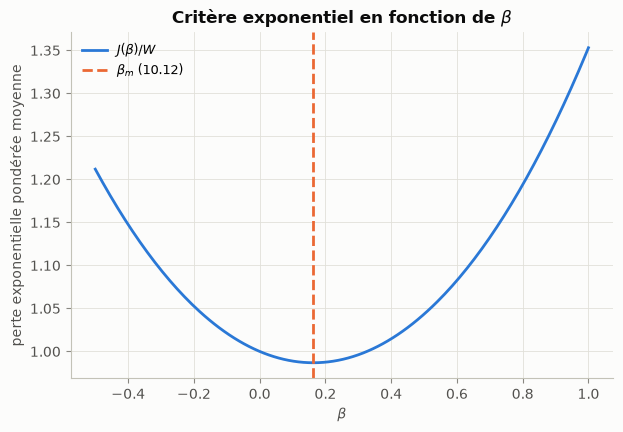

In [3]:
bb = np.linspace(-0.5, 1.0, 200)
plt.figure(figsize=(7, 4.5))
plt.plot(bb, [J(b) / w.sum() for b in bb], color=BLUE, label="$J(\\beta)/W$")
plt.axvline(0.5 * np.log((1 - err) / err), color=ORANGE, ls="--", label="$\\beta_m$ (10.12)")
plt.title("Critère exponentiel en fonction de $\\beta$")
plt.xlabel("$\\beta$")
plt.ylabel("perte exponentielle pondérée moyenne")
plt.legend()
plt.show()

> **À retenir.** Le coefficient optimal est $\beta_m = \frac12\log\frac{1-\mathrm{err}_m}{\mathrm{err}_m}$ ; le
> poids du vote d'AdaBoost est $\alpha_m = 2\beta_m$. Plus le classifieur est précis, plus son
> vote compte.

## Exercice 10.2 : Minimiseur en population de la perte exponentielle

**Énoncé (reformulé).** Démontrer (10.16) : le minimiseur de
$f \mapsto E_{Y\mid x}\big(e^{-Yf(x)}\big)$ est la moitié du log-rapport de cotes
$\frac12\log\frac{P(Y=1\mid x)}{P(Y=-1\mid x)}$.

**Solution.** Fixons $x$ et notons $p = P(Y=1\mid x)\in\,]0,1[$ et $t = f(x)\in\mathbb R$.
$Y$ ne prend que les valeurs $\pm1$, donc (définition de l'espérance d'une variable discrète)

$$\varphi(t) := E_{Y\mid x}\big(e^{-Yt}\big) = p\,e^{-t} + (1-p)\,e^{t}.$$

- $\varphi$ est dérivable, $\varphi'(t) = -p e^{-t} + (1-p)e^{t}$ et $\varphi''(t) = pe^{-t} + (1-p)e^t > 0$ :
  $\varphi$ est strictement convexe.
- $\varphi(t)\to+\infty$ quand $t\to\pm\infty$ (car $p>0$ et $1-p>0$) : le minimum existe et
  est l'unique zéro de $\varphi'$.
- $\varphi'(t) = 0 \iff e^{2t} = \frac{p}{1-p} \iff t = \frac12\log\frac{p}{1-p}$.

Comme $1 - p = P(Y=-1\mid x)$, on obtient $f^*(x) = \frac12\log\frac{P(Y=1\mid x)}{P(Y=-1\mid x)}$ (éq. (10.16)).

**Conséquence (10.17).** En inversant : $e^{2f^*} = p/(1-p)$, donc $p = e^{2f^*}/(1+e^{2f^*}) = 1/(1+e^{-2f^*})$.

> **Remarque.** Si $p = 1$ (ou $p=0$), $\varphi(t) = e^{-t}$ (ou $e^t$) n'a pas de minimum :
> l'infimum est atteint « à l'infini ». C'est ce qui se passe pour la simulation (10.2), où
> les classes sont séparées : la vraie fonction cible est infinie.

In [4]:
ts = np.linspace(-4, 4, 20001)
print("   p   | argmin numérique | (1/2) log(p/(1-p))")
for p in (0.1, 0.3, 0.5, 0.8, 0.95):
    phi = p * np.exp(-ts) + (1 - p) * np.exp(ts)
    print("%5.2f  |  %+.4f         |  %+.4f" % (p, ts[np.argmin(phi)], 0.5 * np.log(p / (1 - p))))

   p   | argmin numérique | (1/2) log(p/(1-p))
 0.10  |  -1.0988         |  -1.0986
 0.30  |  -0.4236         |  -0.4236
 0.50  |  +0.0000         |  +0.0000
 0.80  |  +0.6932         |  +0.6931
 0.95  |  +1.4724         |  +1.4722


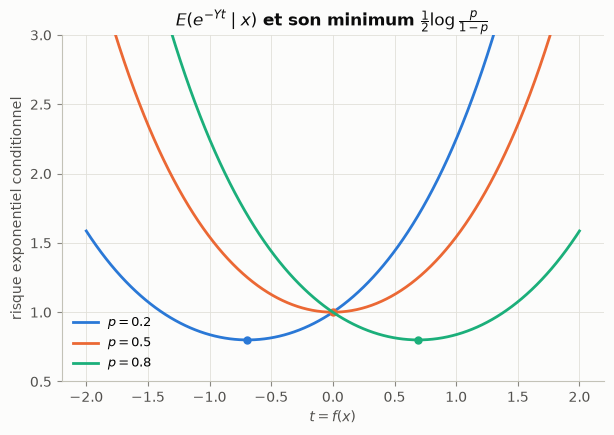

In [5]:
plt.figure(figsize=(7, 4.5))
tt = np.linspace(-2, 2, 300)
for k, p in enumerate((0.2, 0.5, 0.8)):
    plt.plot(tt, p * np.exp(-tt) + (1 - p) * np.exp(tt), color=COLORS[k], label="$p = %.1f$" % p)
    t_star = 0.5 * np.log(p / (1 - p))
    plt.plot(t_star, p * np.exp(-t_star) + (1 - p) * np.exp(t_star), "o", color=COLORS[k])
plt.ylim(0.5, 3)
plt.title("$E(e^{-Yt}\\mid x)$ et son minimum $\\frac{1}{2}\\log\\frac{p}{1-p}$")
plt.xlabel("$t = f(x)$")
plt.ylabel("risque exponentiel conditionnel")
plt.legend()
plt.show()

> **À retenir.** La perte exponentielle estime la moitié du log-rapport de cotes ; son signe
> donne la règle de Bayes et $1/(1+e^{-2f})$ donne une probabilité.

## Exercice 10.3 : Dépendance partielle contre espérance conditionnelle

**Énoncé (reformulé).** Montrer que la moyenne marginale (10.47),
$f_S(X_S) = E_{X_C}f(X_S, X_C)$, retrouve les fonctions additives (10.50)
$f = h_1(X_S) + h_2(X_C)$ et multiplicatives (10.51) $f = h_1(X_S)h_2(X_C)$ (à une constante
additive, resp. multiplicative, près), alors que l'espérance conditionnelle (10.49)
$\tilde f_S(X_S) = E(f(X_S,X_C)\mid X_S)$ ne les retrouve pas.

**Rappel.** Dans (10.47), $X_S = x_S$ est **fixé** et l'espérance porte sur $X_C$ selon sa loi
**marginale** ; dans (10.49), l'espérance porte sur $X_C$ selon sa loi **conditionnelle**
sachant $X_S = x_S$.

**Cas additif.** Par linéarité de l'espérance,

$$f_S(x_S) = E_{X_C}\big[h_1(x_S) + h_2(X_C)\big] = h_1(x_S) + \underbrace{E[h_2(X_C)]}_{\text{constante}}.$$

**Cas multiplicatif.** $h_1(x_S)$ est une constante pour l'espérance en $X_C$, donc

$$f_S(x_S) = h_1(x_S)\,\underbrace{E[h_2(X_C)]}_{\text{constante}}.$$

**Espérance conditionnelle.** Cette fois, on conditionne :

$$\tilde f_S(x_S) = h_1(x_S) + E\big[h_2(X_C)\mid X_S = x_S\big] \quad\text{(cas additif)},\qquad
\tilde f_S(x_S) = h_1(x_S)\,E\big[h_2(X_C)\mid X_S = x_S\big] \quad\text{(cas multiplicatif)}.$$

Le terme $E[h_2(X_C)\mid X_S = x_S]$ est une **fonction de $x_S$** dès que $X_S$ et $X_C$ sont
dépendants : $\tilde f_S$ n'est alors égale à $h_1$ ni à une constante additive près, ni à un
facteur près. Elle ne l'est que si cette fonction est constante, par exemple si $X_S$ et
$X_C$ sont indépendants.

**Exemple.** $(X_1, X_2)$ gaussien centré réduit de corrélation $\rho = 0{,}7$, $S=\{1\}$, $C=\{2\}$,
$h_1(x) = \sin(2x)$, $h_2(x) = x^2 + 1$. On sait que $X_2 \mid X_1 = x \sim \mathcal N(\rho x, 1-\rho^2)$,
donc $E[h_2(X_2)\mid X_1 = x] = \rho^2x^2 + (1-\rho^2) + 1$, alors que $E[h_2(X_2)] = 2$.

In [6]:
rng = np.random.RandomState(0)
rho = 0.7
Z = rng.randn(20000, 2)
X12 = np.c_[Z[:, 0], rho * Z[:, 0] + np.sqrt(1 - rho ** 2) * Z[:, 1]]
h1 = lambda u: np.sin(2 * u)
h2 = lambda u: u ** 2 + 1
f_add = lambda A: h1(A[:, 0]) + h2(A[:, 1])
f_mul = lambda A: h1(A[:, 0]) * h2(A[:, 1])
grid = np.linspace(-2, 2, 41)
cond_h2 = rho ** 2 * grid ** 2 + (1 - rho ** 2) + 1     # E[h2(X2) | X1 = x]

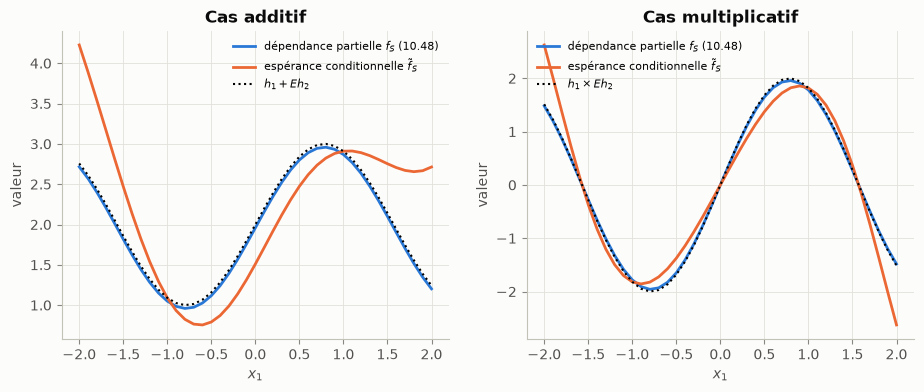

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, f, name, tilde in ((axes[0], f_add, "additif", h1(grid) + cond_h2),
                           (axes[1], f_mul, "multiplicatif", h1(grid) * cond_h2)):
    pdp = partial_dependence_bruteforce(f, X12[:3000], [0], grid[:, None])
    ax.plot(grid, pdp, color=BLUE, label="dépendance partielle $f_S$ (10.48)")
    ax.plot(grid, tilde, color=ORANGE, label="espérance conditionnelle $\\tilde f_S$")
    ref = h1(grid) + 2 if name == "additif" else 2 * h1(grid)
    ax.plot(grid, ref, color="black", ls=":", lw=1.5,
            label="$h_1 + E h_2$" if name == "additif" else "$h_1 \\times E h_2$")
    ax.set(title="Cas %s" % name, xlabel="$x_1$", ylabel="valeur")
    ax.legend(fontsize=8)
plt.show()

La dépendance partielle (estimée par (10.48) sur 3000 observations) colle à $h_1$ à une
constante près ; l'espérance conditionnelle s'en écarte d'un terme quadratique.

> **À retenir.** La dépendance partielle « neutralise » les autres variables en les moyennant
> selon leur loi marginale ; elle retrouve les effets additifs et multiplicatifs. L'espérance
> conditionnelle mélange l'effet de $X_S$ et celui des variables corrélées à $X_S$.

## Exercice 10.4 : AdaBoost avec des arbres

**Énoncé (reformulé).**
(a) Programmer AdaBoost avec des arbres.
(b) Refaire les calculs de la figure 10.2 en traçant l'erreur d'apprentissage et l'erreur
de test, et commenter.
(c) Étudier le nombre d'itérations nécessaire pour que l'erreur de test finisse par remonter.
(d) Modifier l'exemple : classe 1 = $X_1,\dots,X_{10}$ gaussiennes indépendantes centrées
réduites ; classe 2 = même loi **conditionnée** à $\sum_j X_j^2 > 12$. Les classes se
chevauchent désormais fortement. Refaire les expériences et commenter.

### (a) Programme

Le classifieur faible est un arbre de classification pondéré à $J$ feuilles. Nous
réutilisons l'arbre de moindres carrés pondérés du module (pour une cible $\pm1$, le
critère des moindres carrés pondérés est l'indice de Gini pondéré) et nous écrivons la
boucle d'AdaBoost explicitement.

In [8]:
def adaboost_trees(X, y, M, J=2):
    """AdaBoost.M1 (algorithme 10.1) avec des arbres à J feuilles ; y dans {-1, +1}."""
    N = len(y)
    order = RegressionTree.presort(X)          # tri effectué une seule fois
    w = np.full(N, 1.0 / N)                    # 1. poids initiaux
    trees, alphas = [], []
    for m in range(M):                         # 2.
        t = RegressionTree(J).fit(X, y, w, order=order)
        t.value = np.where(t.value >= 0, 1.0, -1.0)    # (a) classifieur G_m
        miss = t.predict(X) != y
        err = np.clip(w[miss].sum() / w.sum(), 1e-12, 1 - 1e-12)   # (b)
        alpha = np.log((1 - err) / err)                             # (c)
        w = w * np.exp(alpha * miss)                                # (d)
        w /= w.sum()
        trees.append(t)
        alphas.append(alpha)
    return trees, np.array(alphas)

def staged_test_errors(trees, alphas, X, y):
    F = np.zeros(len(y))
    errs = []
    for t, a in zip(trees, alphas):
        F += a * t.predict(X)
        errs.append(np.mean(np.where(F >= 0, 1, -1) != y))   # 3. signe du vote pondéré
    return np.array(errs)

Vérification : notre boucle coïncide avec la classe `AdaBoostM1` du module (elle-même
testée contre `AdaBoostClassifier` de scikit-learn).

In [9]:
rng = np.random.RandomState(0)
X, y = simulate_nested_spheres(2000, rng=rng)
Xt, yt = simulate_nested_spheres(10000, rng=rng)
trees, alphas = adaboost_trees(X, y, 50, J=4)
ref = AdaBoostM1(50, n_leaves=4).fit(X, y)
print("mêmes alpha que le module :", np.allclose(alphas, ref.alphas_))

mêmes alpha que le module : True


### (b) Figure 10.2 avec erreurs d'apprentissage et de test

In [10]:
M_b = 400
trees_b, alphas_b = adaboost_trees(X, y, M_b, J=2)
tr_b = staged_test_errors(trees_b, alphas_b, X, y)
te_b = staged_test_errors(trees_b, alphas_b, Xt, yt)

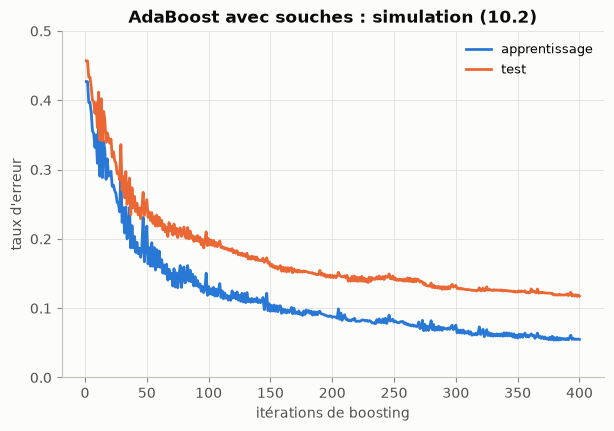

après 400 itérations : apprentissage 0.055, test 0.117


In [11]:
plt.figure(figsize=(7, 4.5))
plt.plot(np.arange(1, M_b + 1), tr_b, color=BLUE, label="apprentissage")
plt.plot(np.arange(1, M_b + 1), te_b, color=ORANGE, label="test")
plt.ylim(0, 0.5)
plt.title("AdaBoost avec souches : simulation (10.2)")
plt.xlabel("itérations de boosting")
plt.ylabel("taux d'erreur")
plt.legend()
plt.show()
print("après %d itérations : apprentissage %.3f, test %.3f" % (M_b, tr_b[-1], te_b[-1]))

**Commentaire.** Les deux erreurs décroissent ensemble ; l'écart entre elles reste modéré.
Le modèle obtenu avec des souches est **additif** (somme de fonctions d'une seule
variable), exactement la structure de la frontière $\sum_j X_j^2 = 9{,}34$ : il y a peu de
variance « gaspillée ». Comme les classes sont séparables (erreur de Bayes nulle), le bruit
est absent et AdaBoost n'a aucune raison de surajuster rapidement.

### (c) Quand l'erreur de test remonte-t-elle ?

Nous poursuivons jusqu'à 3000 itérations avec des souches, et comparons avec des arbres
à 8 feuilles, qui permettent des interactions inutiles et surajustent plus vite.

In [12]:
M_c = 3000
res_c = {}
for J in (2, 8):
    tr_c, al_c = adaboost_trees(X, y, M_c, J=J)
    res_c[J] = (staged_test_errors(tr_c, al_c, X, y), staged_test_errors(tr_c, al_c, Xt, yt))

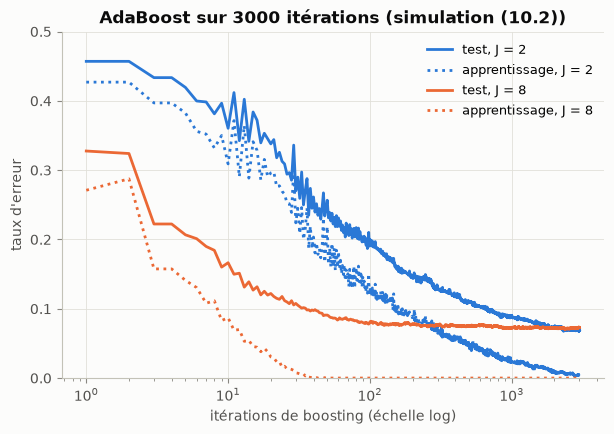

J = 2 : erreur de test minimale 0.067 à m = 2970 ; à m = 3000 : 0.069 ; apprentissage final 0.004
J = 8 : erreur de test minimale 0.070 à m = 2365 ; à m = 3000 : 0.073 ; apprentissage final 0.000


In [13]:
plt.figure(figsize=(7, 4.5))
for k, J in enumerate(res_c):
    trn, tst = res_c[J]
    plt.plot(np.arange(1, M_c + 1), tst, color=COLORS[k], label="test, J = %d" % J)
    plt.plot(np.arange(1, M_c + 1), trn, color=COLORS[k], ls=":", label="apprentissage, J = %d" % J)
plt.xscale("log")
plt.ylim(0, 0.5)
plt.title("AdaBoost sur 3000 itérations (simulation (10.2))")
plt.xlabel("itérations de boosting (échelle log)")
plt.ylabel("taux d'erreur")
plt.legend()
plt.show()
for J in res_c:
    trn, tst = res_c[J]
    print("J = %d : erreur de test minimale %.3f à m = %d ; à m = %d : %.3f ; apprentissage final %.3f"
          % (J, tst.min(), tst.argmin() + 1, M_c, tst[-1], trn[-1]))

**Commentaire.** Avec des souches, l'erreur de test baisse encore à 3000 itérations
(alors que l'erreur d'apprentissage est presque nulle) : il faudrait un nombre
d'itérations bien supérieur pour observer une remontée. Avec des arbres à 8 feuilles,
l'erreur d'apprentissage est **nulle dès une cinquantaine d'itérations**, et pourtant
l'erreur de test continue de diminuer lentement pendant des milliers d'itérations, avant
de se stabiliser ; la remontée, s'il y en a une, est minime. Ce comportement est connu :
sur des problèmes **sans bruit**, AdaBoost est remarquablement résistant au surajustement,
car il continue d'augmenter les marges $y_if(x_i)$ même après avoir classé parfaitement
l'échantillon d'apprentissage.

### (d) Classes qui se chevauchent

Classe 1 : $X\sim\mathcal N(0, I_{10})$. Classe 2 : $X\sim\mathcal N(0, I_{10})$ conditionné à
$\sum_j X_j^2 > 12$, que l'on simule par **rejet** (on tire des gaussiennes et on garde
celles qui vérifient la condition, de probabilité $P(\chi^2_{10} > 12)\approx 0{,}285$).
Nous prenons des classes de même effectif (1000 + 1000 en apprentissage).

**Erreur de Bayes.** Avec des probabilités a priori égales, les densités sont
$\phi(x)$ et $\phi(x)I(\|x\|^2>12)/0{,}285$. Si $\|x\|^2 \le 12$ seule la classe 1 est possible ;
sinon la densité de la classe 2 est $1/0{,}285 > 1$ fois celle de la classe 1. La règle de
Bayes prédit donc « classe 2 » si et seulement si $\|x\|^2 > 12$, et se trompe sur les points
de la classe 1 tels que $\|x\|^2>12$ : erreur $= \frac12\times 0{,}285 \approx 0{,}142$.

In [14]:
def simulate_overlap(n_per_class, rng):
    X1 = rng.randn(n_per_class, 10)
    X2 = np.empty((0, 10))
    while len(X2) < n_per_class:
        cand = rng.randn(4 * n_per_class, 10)
        X2 = np.vstack([X2, cand[(cand ** 2).sum(1) > 12]])
    X = np.vstack([X1, X2[:n_per_class]])
    y = np.r_[-np.ones(n_per_class), np.ones(n_per_class)].astype(int)
    return X, y

rng = np.random.RandomState(1)
Xo, yo = simulate_overlap(1000, rng)
Xo_t, yo_t = simulate_overlap(5000, rng)
bayes_err = np.mean(np.where((Xo_t ** 2).sum(1) > 12, 1, -1) != yo_t)
print("P(chi2_10 > 12) = %.4f ; erreur de Bayes théorique = %.4f ; empirique (test) = %.4f"
      % (stats.chi2.sf(12, 10), stats.chi2.sf(12, 10) / 2, bayes_err))

P(chi2_10 > 12) = 0.2851 ; erreur de Bayes théorique = 0.1425 ; empirique (test) = 0.1407


In [15]:
M_d = 1000
res_d = {}
for J in (2, 8):
    tr_d, al_d = adaboost_trees(Xo, yo, M_d, J=J)
    res_d[J] = (staged_test_errors(tr_d, al_d, Xo, yo), staged_test_errors(tr_d, al_d, Xo_t, yo_t))

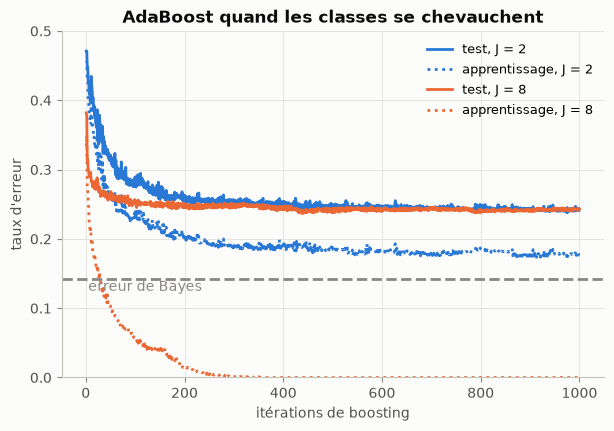

J = 2 : test min 0.238 (m = 974), test final 0.243, apprentissage final 0.176
J = 8 : test min 0.236 (m = 439), test final 0.243, apprentissage final 0.000


In [16]:
plt.figure(figsize=(7, 4.5))
for k, J in enumerate(res_d):
    trn, tst = res_d[J]
    plt.plot(np.arange(1, M_d + 1), tst, color=COLORS[k], label="test, J = %d" % J)
    plt.plot(np.arange(1, M_d + 1), trn, color=COLORS[k], ls=":", label="apprentissage, J = %d" % J)
plt.axhline(stats.chi2.sf(12, 10) / 2, color=GRAY, ls="--")
plt.text(5, 0.125, "erreur de Bayes", color=GRAY)
plt.ylim(0, 0.5)
plt.title("AdaBoost quand les classes se chevauchent")
plt.xlabel("itérations de boosting")
plt.ylabel("taux d'erreur")
plt.legend()
plt.show()
for J in res_d:
    trn, tst = res_d[J]
    print("J = %d : test min %.3f (m = %d), test final %.3f, apprentissage final %.3f"
          % (J, tst.min(), tst.argmin() + 1, tst[-1], trn[-1]))

**Commentaire.** Le comportement change nettement :

- avec des arbres à 8 feuilles, l'erreur d'apprentissage tombe à **0**, bien en dessous de
  l'erreur de Bayes (14 %) : le modèle apprend le bruit ;
- l'erreur de test atteint vite un plateau autour de 24 %, loin de l'erreur de Bayes, et
  n'en bouge plus (au mieux, elle remonte légèrement après son minimum) : les itérations
  supplémentaires ne servent qu'à ajuster le bruit ;
- l'écart entre apprentissage et test, faible dans la question (b), est ici énorme.

Avec des classes qui se chevauchent, AdaBoost concentre ses poids sur les points « du
mauvais côté » de la frontière de Bayes, qu'il est impossible de bien classer.
À titre de comparaison, le gradient boosting avec la déviance et un rétrécissement fait à
peine mieux sur cet échantillon : avec 2000 observations en dimension 10, estimer la
frontière sphérique $\|x\|^2 = 12$ au milieu d'un fort recouvrement est réellement difficile.

In [17]:
gb_o = GradientBoosting("deviance", 1000, 4, learning_rate=0.05).fit(Xo, (yo + 1) // 2)
its_o, _, err_o = gb_o.staged_scores(Xo_t, (yo_t + 1) // 2, every=50)
print("gradient boosting (déviance, J = 4, nu = 0,05) : erreur de test minimale %.3f (m = %d)"
      % (err_o.min(), its_o[err_o.argmin()]))

gradient boosting (déviance, J = 4, nu = 0,05) : erreur de test minimale 0.230 (m = 350)


> **À retenir.** Sans bruit, AdaBoost surajuste très lentement, même après avoir annulé
> l'erreur d'apprentissage ; avec des classes qui se chevauchent, il apprend le bruit,
> l'écart apprentissage/test devient énorme et les itérations supplémentaires sont inutiles
> (voire nuisibles) : le nombre d'itérations doit être choisi par validation.

## Exercice 10.5 : Perte exponentielle multiclasse (Zhu et al., 2005)

**Énoncé (reformulé).** Pour $K$ classes, on code la réponse par le vecteur
$Y = (Y_1,\dots,Y_K)^T$ avec $Y_k = 1$ si $G = \mathcal G_k$ et $Y_k = -\frac{1}{K-1}$ sinon (éq. (10.55)).
Soit $f = (f_1,\dots,f_K)^T$ avec $\sum_k f_k = 0$ et $L(Y, f) = \exp\big(-\frac1K Y^Tf\big)$ (éq. (10.56)).
(a) Avec des multiplicateurs de Lagrange, trouver le minimiseur en population $f^*$ de
$E\,L(Y,f)$ sous la contrainte de somme nulle et le relier aux probabilités des classes.
(b) Montrer que le boosting multiclasse avec cette perte conduit à un algorithme de
repondération analogue à AdaBoost.

### (a) Minimiseur en population

*Simplification de $Y^Tf$.* Si l'observation est dans la classe $k$ :

$$Y^Tf = f_k - \frac{1}{K-1}\sum_{\ell\ne k}f_\ell = f_k - \frac{1}{K-1}(-f_k) = \frac{K}{K-1}f_k,$$

en utilisant $\sum_{\ell\ne k}f_\ell = -f_k$ (contrainte de somme nulle). Donc
$L = \exp\big(-\frac{f_k}{K-1}\big)$ et, en notant $p_k = P(G = \mathcal G_k\mid x)$,

$$E\big[L(Y,f)\mid x\big] = \sum_{k=1}^K p_k\, e^{-f_k/(K-1)}.$$

*Lagrangien.* On minimise $\sum_k p_k e^{-f_k/(K-1)}$ sous $\sum_k f_k = 0$ :

$$\mathcal L(f, \lambda) = \sum_{k=1}^K p_k e^{-f_k/(K-1)} - \lambda\sum_{k=1}^K f_k.$$

La fonction à minimiser est strictement convexe (somme d'exponentielles de fonctions
affines, avec $p_k > 0$) et la contrainte est linéaire : la condition du premier ordre est
nécessaire et suffisante. En dérivant par rapport à $f_k$ :

$$-\frac{p_k}{K-1}e^{-f_k/(K-1)} - \lambda = 0 \iff e^{-f_k/(K-1)} = \frac{-\lambda(K-1)}{p_k}
\iff f_k = (K-1)\big[\log p_k - \log(-\lambda(K-1))\big].$$

(Nécessairement $\lambda < 0$.) La contrainte $\sum_k f_k = 0$ donne
$\log(-\lambda(K-1)) = \frac1K\sum_\ell\log p_\ell$, d'où

$$f_k^*(x) = (K-1)\Big(\log p_k(x) - \frac1K\sum_{\ell=1}^K \log p_\ell(x)\Big).$$

*Lien avec les probabilités.* $e^{f_k^*/(K-1)} = p_k\,/\,\big(\prod_\ell p_\ell\big)^{1/K}$, donc

$$p_k(x) = \frac{e^{f^*_k(x)/(K-1)}}{\sum_{\ell=1}^K e^{f^*_\ell(x)/(K-1)}},$$

une transformation « softmax » (comparer à (10.21)). Pour $K=2$, $f_1^* = \frac12\log\frac{p_1}{p_2}$ :
on retrouve (10.16).

**Vérification numérique** : minimisation sous contrainte avec `scipy` pour $K = 4$.

In [ ]:
p = np.array([0.1, 0.2, 0.3, 0.4])
K = len(p)
obj = lambda f: np.sum(p * np.exp(-f / (K - 1)))
cons = {"type": "eq", "fun": lambda f: f.sum()}
sol = optimize.minimize(obj, np.zeros(K), constraints=[cons], method="SLSQP", options={"ftol": 1e-14})
f_star = (K - 1) * (np.log(p) - np.log(p).mean())
print("numérique :", np.round(sol.x, 5))
print("formule   :", np.round(f_star, 5))
print("softmax(f*/(K-1)) :", np.round(np.exp(f_star / (K - 1)) / np.exp(f_star / (K - 1)).sum(), 5))

### (b) L'algorithme de repondération (SAMME)

On ajoute pas à pas des termes $\beta\, g(x)$ où $g$ est le **codage** d'un classifieur $G$ à
valeurs dans $\{1,\dots,K\}$ : $g_k(x) = 1$ si $G(x) = k$, $-\frac1{K-1}$ sinon (même codage que $Y$,
donc $\sum_k g_k = 0$). Comme pour AdaBoost,

$$\sum_i \exp\Big(-\tfrac1K y_i^T\big(f_{m-1}(x_i) + \beta g(x_i)\big)\Big) = \sum_i w_i\exp\Big(-\tfrac{\beta}{K}y_i^Tg(x_i)\Big),
\qquad w_i = \exp\Big(-\tfrac1K y_i^Tf_{m-1}(x_i)\Big).$$